# NB1 — Audit of the HKUST dataset

Describes the data before any modelling and reproduces, from code, the claims of the review audit of 18 Nov 2026 (F01, F05, F06, F16) and of the sensor audit of 31 Oct 2026 (F09). Nothing is tuned here.
Outputs: `results/nb1_audit/` (tables, draft figures, summary.json), written all-or-nothing.

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np, pandas as pd
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT / 'src'))
from pvcold import config as C, audit as A, io_hkust as io
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)
t0 = time.time()

## 1. Units from the Brick metadata
AC rating from the inverter model name, DC rating from module count × watt-peak (D01). Brick azimuth is converted to the pvlib convention (F15).

In [2]:
inv, st, inv_map, st_map = A.units()
print(f'{len(st)} stations, {len(inv)} inverters; files matched: {len(inv_map)} inverter, {len(st_map)} site')
inv[['station', 'inverter', 'inverter_model', 'AC_kW', 'module_models', 'n_modules', 'DC_kWp', 'DC_AC']].round(3)

60 stations, 67 inverters; files matched: 44 inverter, 60 site


,station,inverter,inverter_model,AC_kW,module_models,n_modules,DC_kWp,DC_AC
0,CYT__Station_1_,CYT__Station_1__Inverter,Sunny_Tripower_25000TL_JP_30,25.0,JKM395M_6RL3_V,77.0,30.415,1.217
1,CYT__Station_2_,CYT__Station_2__Inverter,Sunny_Tripower_25000TL_JP_30,25.0,JKM395M_6RL3_V,77.0,30.415,1.217
2,Indoor_Sport_Center,Indoor_Sport_Center_Inverter,Sunny_Tripower_STP_10_0,10.0,JKM365N_6TL3,120.0,43.800,4.380
3,LSK_North,LSK_North_Inverter,SolarEdge_SE55K,55.0,JKM390M_6RL3_TV,170.0,66.300,1.205
4,LSK_South,LSK_South_Inverter,SolarEdge_SE25K,25.0,JKM390M_6RL3_TV,72.0,28.080,1.123
...,...,...,...,...,...,...,...,...
62,Zone_J1,Zone_J1_Inverter,SolarEdge_SE25K,25.0,JKM365N_6TL3_V,70.0,25.550,1.022
63,Zone_J2,Zone_J2_Inverter,SolarEdge_SE50K,50.0,JKM365N_6TL3_V,175.0,63.875,1.278
64,Zone_L1__Station_1_,Zone_L1__Station_1__Inverter,Sunny_Tripower_25000TL_30,25.0,JKM395M_6RL3_V,75.0,29.625,1.185
65,Zone_L1__Station_2_,Zone_L1__Station_2__Inverter,Sunny_Tripower_25000TL_30,25.0,JKM395M_6RL3_V,75.0,29.625,1.185


## 2. Inventory of the inverter files (5 min)

In [3]:
ii, daily_inv = A.inventory_inverters(inv)
print('timestamp formats:', ii.time_format.value_counts().to_dict())
print('rows per day (mode):', ii.rows_per_day_mode.value_counts().to_dict(),
      '| earliest slot:', ii.earliest_slot.unique(), '| latest slot:', ii.latest_slot.unique())
print('duplicated stamps:', ii.duplicated_stamps.sum(), '| negative power values:', ii.negative_P.sum())
print('NA share of power: median %.3f, max %.3f' % (ii.na_share_P.median(), ii.na_share_P.max()))
print('not producing on the first day:', ii.loc[ii.producing_on_first_day == False, 'file'].tolist())
ii.sort_values('first')[['file', 'time_format', 'first', 'last', 'days', 'na_share_P', 'P_p999_kW', 'AC_kW', 'p999_over_AC']]

timestamp formats: {'iso': 31, 'ymd': 13}
rows per day (mode): {144: 44} | earliest slot: ['06:00'] | latest slot: ['17:55']
duplicated stamps: 0 | negative power values: 0
NA share of power: median 0.062, max 0.129
not producing on the first day: ['Zone A2_Inverter_2']


,file,time_format,first,last,days,na_share_P,P_p999_kW,AC_kW,p999_over_AC
5,LSK South_Inverter,ymd,2021-05-01 06:00:00,2023-12-31 17:55:00,975,0.113462,24.980500,25.0,0.999220
4,LSK North_Inverter,iso,2021-05-04 07:00:00,2023-12-31 17:55:00,972,0.057382,55.209228,55.0,1.003804
16,SQ1_Inverter,iso,2021-05-07 07:00:00,2023-12-31 17:55:00,969,0.059861,27.660829,27.6,1.002204
25,UG Hall6_Inverter,iso,2021-05-11 07:00:00,2023-12-31 17:55:00,965,0.058475,25.005000,25.0,1.000200
19,SQ4_Inverter,iso,2021-05-12 07:00:00,2023-12-31 17:55:00,964,0.057527,33.328000,33.3,1.000841
17,SQ2_Inverter,iso,2021-05-12 07:00:00,2023-12-31 17:55:00,964,0.060358,32.451255,33.3,0.974512
26,UG Hall7_Inverter,ymd,2021-05-17 06:00:00,2023-12-31 17:55:00,959,0.061711,25.001427,25.0,1.000057
18,SQ3_Inverter,iso,2021-05-19 07:00:00,2023-12-31 17:55:00,957,0.058304,33.308324,33.3,1.000250
23,UG Hall3_Inverter,ymd,2021-05-21 06:00:00,2023-12-31 17:55:00,955,0.065489,24.962487,25.0,0.998499
24,UG Hall4_Inverter,ymd,2021-05-21 07:00:00,2023-12-31 17:55:00,955,0.065414,25.065000,25.0,1.002600


## 3. AC rating vs observed power
Guide §2: the AC rating matches the 99.9th percentile of power within 2% for most units; the others are metadata errors or units that never reach their limit.

In [4]:
mc = A.metadata_check(ii, inv)
print('within 2%:', int(mc.within_2pct.sum()), 'of', len(mc))
mc.loc[~mc.within_2pct, ['file', 'inverter_model', 'AC_kW', 'DC_kWp', 'DC_AC', 'P_p999_kW', 'P_max_kW', 'p999_over_AC']].round(3)

within 2%: 33 of 44


,file,inverter_model,AC_kW,DC_kWp,DC_AC,P_p999_kW,P_max_kW,p999_over_AC
21,UG Hall2 2F_Inverter,SolarEdge_SE25K,25.0,23.400,0.936,19.142,24.074,0.766
10,SQ567_Inverter,SolarEdge_SE55K,55.0,47.970,0.872,45.812,49.923,0.833
42,Zone J2_Inverter,SolarEdge_SE50K,50.0,63.875,1.278,45.965,49.962,0.919
17,SQ Block S_Inverter,SolarEdge_SE33_3K,33.3,32.850,0.986,31.648,33.422,0.950
43,Zone L2_Inverter,SolarEdge_SE10K,10.0,12.045,1.204,9.704,10.607,0.970
7,SQ2_Inverter,SolarEdge_SE33_3K,33.3,33.540,1.007,32.451,33.645,0.975
14,SQ Apartment37-48_Inverter,SolarEdge_SE12_5K,12.5,14.820,1.186,13.114,13.447,1.049
22,UG Hall2 RF_Inverter,SolarEdge_SE8K,8.0,10.140,1.268,8.413,8.937,1.052
38,Zone A7_Inverter,SolarEdge_SE10K,10.0,12.775,1.278,10.615,10.884,1.061
40,Zone D_Inverter_2,SolarEdge_SE25K,25.0,25.740,1.030,49.906,50.991,1.996


## 4. Site files and weather files

In [5]:
ac_station = pd.concat([st.set_index('site_file_15min')['rated_kW_metadata'].dropna(),
                        st.set_index('site_file_1h')['rated_kW_metadata'].dropna()])
s15, frames15 = A.inventory_sites('15min', ac_station)
s1h, _ = A.inventory_sites('1h', ac_station)
for lab, s in [('15 min', s15), ('1 h', s1h)]:
    print(lab, '| formats:', s.time_format.value_counts().to_dict(), '| not starting on the 1st:',
          int((~s.starts_on_1st).sum()), 'of', len(s), '| slots', s.earliest_slot.min(), '-', s.latest_slot.max())
wi = A.inventory_weather()
wi

15 min | formats: {'iso': 34, 'ymd': 3} | not starting on the 1st: 5 of 37 | slots 00:00 - 23:45
1 h | formats: {'iso': 16, 'ymd': 7} | not starting on the 1st: 23 of 23 | slots 00:00 - 23:00


,variable,year,time_format,rows,expected_rows,missing_rows,na_values,duplicated_stamps,min,max
0,ghi,2021,ymd,525598,525600,2,0,0,0.00000,1021.20000
1,ghi,2022,ymd,522524,525600,3076,0,0,0.00000,1092.60000
2,ghi,2023,ymd,519670,525600,5930,0,0,0.00000,3608.60000
3,temp,2021,ymd,525518,525600,82,0,0,5.40850,37.62600
4,temp,2022,ymd,522524,525600,3076,0,0,5.54240,38.58500
5,temp,2023,ymd,519670,525600,5930,0,0,6.38020,39.74400
6,rh,2021,ymd,525598,525600,2,0,0,0.00049,99.88700
7,rh,2022,ymd,522397,525600,3203,0,0,18.00900,99.98500
8,rh,2023,ymd,519670,525600,5930,0,0,0.10069,99.98900
9,slp,2021,ymd,525598,525600,2,0,0,999.17913,1012.23913


## 5. Start dates (D08) and the review-audit claims

In [6]:
stt = A.start_table(inv, st, ii, s15)
stt

,station,site_file,n_inverter_files,connection_date,first_inverter_day,site_first_row,site_first_power_day,earliest_production_day,earliest_source,left_censored_by_rule,days_connection_to_earliest,days_site_before_inverter
0,LSK_South,LSK South,1,2021-04-30,2021-05-01,2021-06-01,2021-06-01,2021-05-01,inverter,True,1,-31
1,LSK_North,LSK North,1,2021-04-30,2021-05-04,2021-06-01,2021-06-01,2021-05-04,inverter,False,4,-28
2,SQ1,SQ1,1,2021-04-30,2021-05-07,2021-06-01,2021-06-01,2021-05-07,inverter,False,7,-25
3,UG_Hall6,UG Hall6,1,2021-04-30,2021-05-11,2021-06-01,2021-06-01,2021-05-11,inverter,False,11,-21
4,SQ2,SQ2,1,2021-04-30,2021-05-12,2021-06-01,2021-06-01,2021-05-12,inverter,False,12,-20
5,SQ4,SQ4,1,2021-04-30,2021-05-12,2021-06-01,2021-06-01,2021-05-12,inverter,False,12,-20
6,UG_Hall7,UG Hall7,1,2021-06-01,2021-05-17,2021-06-01,2021-06-01,2021-05-17,inverter,False,-15,-15
7,SQ3,SQ3,1,2021-06-01,2021-05-19,2021-06-01,2021-06-01,2021-05-19,inverter,False,-13,-13
8,UG_Hall4,UG Hall4,1,2021-06-01,2021-05-21,2021-07-01,2021-07-01,2021-05-21,inverter,False,-11,-41
9,UG_Hall3,UG Hall3,1,2021-06-01,2021-05-21,2021-07-01,2021-07-01,2021-05-21,inverter,False,-11,-41


In [7]:
es, es_sum = A.evening_share(frames15)
per_station = {k: v.loc[v.time.dt.hour >= 18, 'E_kWh'].sum() / v.E_kWh.sum() for k, v in frames15.items() if v.E_kWh.sum() > 0}
es_sum['median_share_per_station_whole_period'] = float(np.median(list(per_station.values())))
es_sum['max_share_per_station_whole_period'] = float(np.max(list(per_station.values())))
print(json.dumps(es_sum, indent=1))
zd = A.zone_d_ratio(frames15)
zd

{
 "median_share_all_station_months": 0.0006050695272655476,
 "max_calendar_month_median": 0.005419358180094465,
 "argmax_calendar_month": 6,
 "max_station_month": 0.007410147262369156,
 "n_station_months": 949,
 "median_share_per_station_whole_period": 0.0018812474843108555,
 "max_share_per_station_whole_period": 0.0026777248644496814
}


,month,days,median_ratio,inv1_days
0,2022-01,12,1.723320,0
1,2022-02,28,1.706612,0
2,2022-03,31,1.717733,0
3,2022-04,30,1.685239,0
4,2022-05,31,1.681166,0
5,2022-06,30,1.694852,0
6,2022-07,31,1.669567,0
7,2022-08,31,1.671769,0
8,2022-09,30,1.670070,0
9,2022-10,31,1.729805,0


## 6. The pyranometer against CAMS all-sky GHI, Ineichen clear sky and the fleet (F09, D19)
Days with a dead sensor (sensor / CAMS below 0.3) are left out of the change-point search. The final drift boundary is fixed in NB3 on the fleet index (D10); this is the audit-level date.

In [8]:
altitude = float(np.median(st.altitude_m.dropna()))
sd, sm = A.sensor_tables(daily_inv, inv, altitude)
dead = sd['ratio_sensor_cams'] < 0.3
print('campus altitude used for clear sky: %.0f m | dead-sensor days: %d (%s to %s)' % (
      altitude, dead.sum(), sd.index[dead].min().date(), sd.index[dead].max().date()))
cp = {k: A.dominant_change(sd.loc[~dead, k]) for k in ['ratio_sensor_cams', 'ratio_sensor_fleet', 'ratio_cams_fleet']}
print(json.dumps(cp, indent=1))
sd.groupby(sd.index.year)[['ratio_sensor_cams', 'ratio_sensor_fleet', 'ratio_cams_fleet']].median().round(3)

campus altitude used for clear sky: 124 m | dead-sensor days: 77 (2021-03-02 to 2022-05-23)


{
 "ratio_sensor_cams": {
  "date": "2023-02-14",
  "before": 0.7564794907568262,
  "after": 1.1661471912043553,
  "n_days": 1012
 },
 "ratio_sensor_fleet": {
  "date": "2023-02-17",
  "before": 0.9010259269441839,
  "after": 1.5311351938136668,
  "n_days": 948
 },
 "ratio_cams_fleet": {
  "date": "2023-03-14",
  "before": 1.1709522952573417,
  "after": 1.2647298620238339,
  "n_days": 948
 }
}


,ratio_sensor_cams,ratio_sensor_fleet,ratio_cams_fleet
day,,,
2021,0.721,0.874,1.176
2022,0.762,0.916,1.171
2023,1.125,1.504,1.240


In [9]:
sm.round(3)

,night_offset_median,noon_p95_sensor_over_ineichen,noon_p95_cams_over_ineichen,spikes_above_bsrn,below_minus2,sensor_max
month,,,,,,
2021-01,2.646,0.924,1.044,0,0,866.970
2021-02,2.866,0.892,1.015,0,0,915.070
2021-03,3.858,0.158,0.978,0,0,602.730
2021-04,3.306,0.013,1.014,0,0,32.285
2021-05,2.644,0.835,1.045,0,0,963.880
2021-06,4.628,0.840,1.023,0,0,944.940
2021-07,4.298,0.838,1.031,0,0,1019.100
2021-08,5.291,0.894,1.038,0,0,1021.200
2021-09,1.984,0.889,1.037,0,0,1018.300


## 7. Draft figures

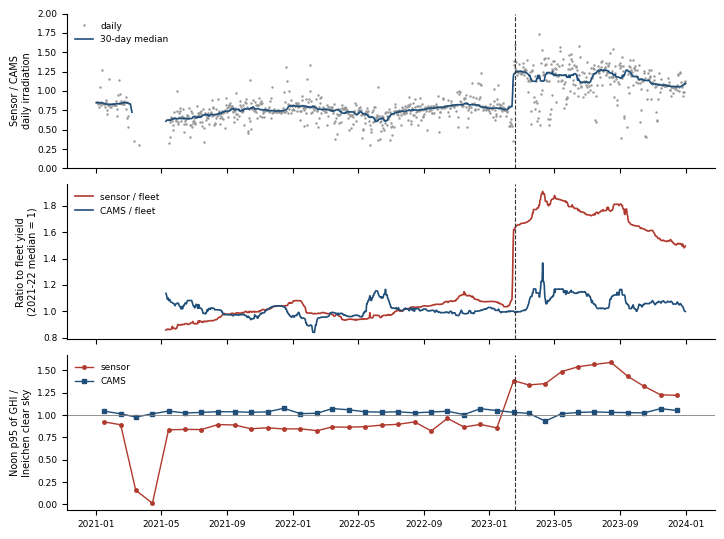

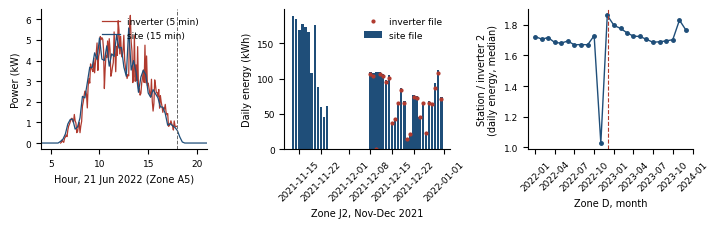

In [10]:
f_sensor = A.fig_sensor(sd.loc[~dead], sm, cp['ratio_sensor_fleet']['date'])
f_quirks = A.fig_quirks(frames15, zd)

## 8. Outputs (all-or-nothing)

In [11]:
summary = {
    'notebook': 'NB1_hkust_audit', 'environment': A.versions(), 'runtime_s': round(time.time() - t0, 1),
    'n_stations': len(st), 'n_inverters_metadata': len(inv), 'n_inverter_files': len(ii),
    'inverter_time_formats': ii.time_format.value_counts().to_dict(),
    'site_time_formats_15min': s15.time_format.value_counts().to_dict(),
    'site_time_formats_1h': s1h.time_format.value_counts().to_dict(),
    'inverter_rows_per_day_mode': ii.rows_per_day_mode.value_counts().to_dict(),
    'inverter_slots': [ii.earliest_slot.min(), ii.latest_slot.max()],
    'inverter_na_share_median': float(ii.na_share_P.median()), 'inverter_na_share_max': float(ii.na_share_P.max()),
    'not_producing_first_day': ii.loc[ii.producing_on_first_day == False, 'file'].tolist(),
    'ac_within_2pct': int(mc.within_2pct.sum()), 'ac_checked': int(len(mc)),
    'site15_not_on_1st': int((~s15.starts_on_1st).sum()), 'site1h_not_on_1st': int((~s1h.starts_on_1st).sum()),
    'evening_share': es_sum, 'campus_altitude_m': altitude,
    'dead_sensor_days': int(dead.sum()), 'dead_sensor_first': str(sd.index[dead].min().date()),
    'dead_sensor_last': str(sd.index[dead].max().date()), 'sensor_change_points_audit': cp,
    'sensor_ratio_yearly_median': sd.groupby(sd.index.year)[['ratio_sensor_cams', 'ratio_sensor_fleet',
                                   'ratio_cams_fleet']].median().round(4).to_dict(),
    'left_censored_by_rule': stt.loc[stt.left_censored_by_rule, 'station'].tolist(),
}
tables = {'units_inverters': inv, 'units_stations': st, 'inventory_inverters': ii, 'metadata_check': mc,
          'inventory_sites_15min': s15, 'inventory_sites_1h': s1h, 'inventory_weather': wi,
          'start_dates': stt, 'evening_share': es, 'zone_d_ratio': zd,
          'sensor_daily': sd.reset_index(names='day'), 'sensor_monthly': sm.reset_index(names='month')}
out = A.write_outputs('nb1_audit', tables, summary, {'sensor_drift': f_sensor, 'quirks': f_quirks})
print('written to', out, '|', sorted(p.name for p in out.iterdir()))

written to C:\Users\Dell\Desktop\phd_ehtp\pv paper\results\nb1_audit | ['evening_share.csv', 'figures', 'inventory_inverters.csv', 'inventory_sites_15min.csv', 'inventory_sites_1h.csv', 'inventory_weather.csv', 'metadata_check.csv', 'sensor_daily.csv', 'sensor_monthly.csv', 'start_dates.csv', 'summary.json', 'units_inverters.csv', 'units_stations.csv', 'zone_d_ratio.csv']
